# Advección periódica: PINN base frente a PCA espacial

Primer benchmark fuera de Burgers. Se usa la ecuación `u_t + c u_x = 0` en `x ∈ [-1,1]`, con `c=1` y frontera periódica. La solución analítica se genera desde `u0(x)=sin(pi*x)+0.5*cos(2*pi*x)` mediante `u(x,t)=u0(x-c*t)`.


## Protocolo

- Diez semillas; 2000 pasos de entrenamiento por modelo.
- Misma partición temporal, minibatches, puntos de colocación PDE, tiempos de frontera y observaciones iniciales para la pareja de cada semilla.
- PCA se ajusta solo con snapshots espaciales de tiempos de entrenamiento y conserva al menos 99% de varianza.
- Ambas redes autodiferencian `u_t + c*u_x` con JAX e incluyen una penalización de periodicidad `u(-1,t)-u(1,t)`.
- Las cantidades de parámetros se emparejan dentro de 5%; tiempo de compilación se mide aparte y el pipeline PCA incluye el ajuste de la base.
- El residuo de prueba se calcula con el mismo operador de diferencias finitas en la malla para ambos modelos.


In [1]:
from pathlib import Path
import json, sys
import pandas as pd
from IPython.display import SVG, display

ROOT = Path.cwd()
while not (ROOT / "pyproject.toml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))
RUN_DIR = ROOT / "results" / "advection" / "base_vs_pca" / "initial_pilot_10_seeds_v1"
CONFIG = json.loads((RUN_DIR / "config.json").read_text(encoding="utf-8"))
RESULT = json.loads((RUN_DIR / "summary.json").read_text(encoding="utf-8"))
METRICS = pd.read_csv(RUN_DIR / "metrics.csv")
TRAJECTORIES = pd.read_csv(RUN_DIR / "validation_trajectories.csv")
print(f"JAX {RESULT['runtime']['jax']} | {RESULT['runtime']['device']}")
print(f"c={RESULT['data']['velocity']}; grid={RESULT['data']['shape_x_t']}; seeds={len(CONFIG['seeds'])}; steps={CONFIG['steps']}")


JAX 0.12.0.1 | cpu:0
c=1.0; grid=[256, 100]; seeds=10; steps=2000


## Resultados en prueba


In [2]:
rows = []
for model, stats in RESULT["summary"].items():
    rows.append({
        "Modelo": model, "k": None if stats["k"] is None else stats["k"]["mean"],
        "Varianza retenida": None if stats["retained_variance"] is None else stats["retained_variance"]["mean"],
        "Parámetros": stats["parameters_mean"],
        "RMSE": f"{stats['test_rmse']['mean']:.4f} ± {stats['test_rmse']['std']:.4f}",
        "Error relativo L2": f"{stats['test_relative_l2']['mean']:.4f} ± {stats['test_relative_l2']['std']:.4f}",
        "Residuo RMS": f"{stats['test_pde_residual_rms']['mean']:.4f} ± {stats['test_pde_residual_rms']['std']:.4f}",
        "Defecto periódico RMS": f"{stats['test_periodic_boundary_rms']['mean']:.4g} ± {stats['test_periodic_boundary_rms']['std']:.2g}",
        "Pipeline": f"{stats['pipeline_seconds']['mean']:.3f} ± {stats['pipeline_seconds']['std']:.3f} s",
    })
display(pd.DataFrame(rows))


Modelo,k,Varianza retenida,Parámetros,RMSE,Error relativo L2,Residuo RMS,Defecto periódico RMS,Pipeline
PINN base,—,—,8577,0.0426 ± 0.0064,0.0540 ± 0.0080,0.0120 ± 0.0024,0.0388 ± 0.0082,3.113 ± 0.046 s
PCA AD,3.0,99.661%,8643,0.0889 ± 0.0143,0.1125 ± 0.0180,0.4933 ± 0.0714,5.659e-08 ± 1.2e-08,2.693 ± 0.128 s


## Diferencias pareadas PCA − base


In [3]:
rows = []
for metric, label in [("test_relative_l2", "Error relativo L2"),
                      ("test_pde_residual_rms", "Residuo advección RMS"),
                      ("test_periodic_boundary_rms", "Defecto periódico RMS"),
                      ("pipeline_seconds", "Tiempo pipeline")]:
    value = RESULT["paired_differences_PCA_minus_base"][metric]
    rows.append({"Métrica": label, "Diferencia media PCA − base": value["PCA_minus_base_mean"],
                 "Semillas donde PCA fue menor": f"{value['PCA_better_count']}/{value['n']}"})
display(pd.DataFrame(rows))


Métrica,Diferencia media PCA − base,Semillas donde PCA fue menor
Error relativo L2,0.058538,0/10
Residuo advección RMS,0.48129,0/10
Defecto periódico RMS,-0.038805,10/10
Tiempo pipeline,-0.41981,10/10


## Comparación agregada


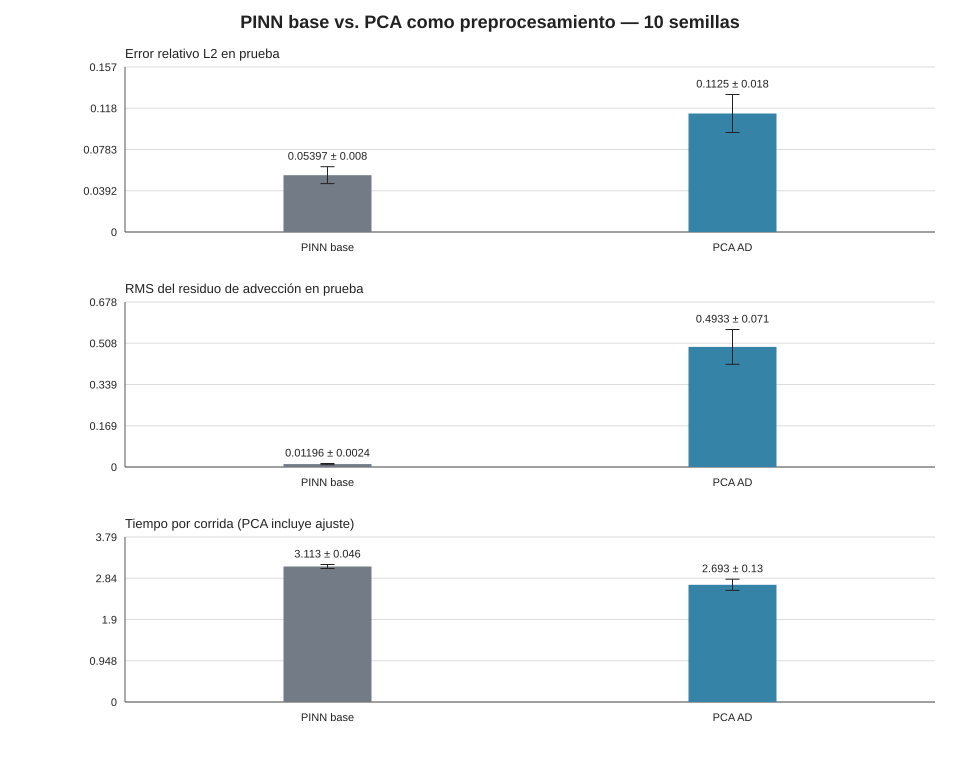

In [4]:
display(SVG(filename=str(RUN_DIR / "comparison.svg")))


## Error de validación frente al tiempo


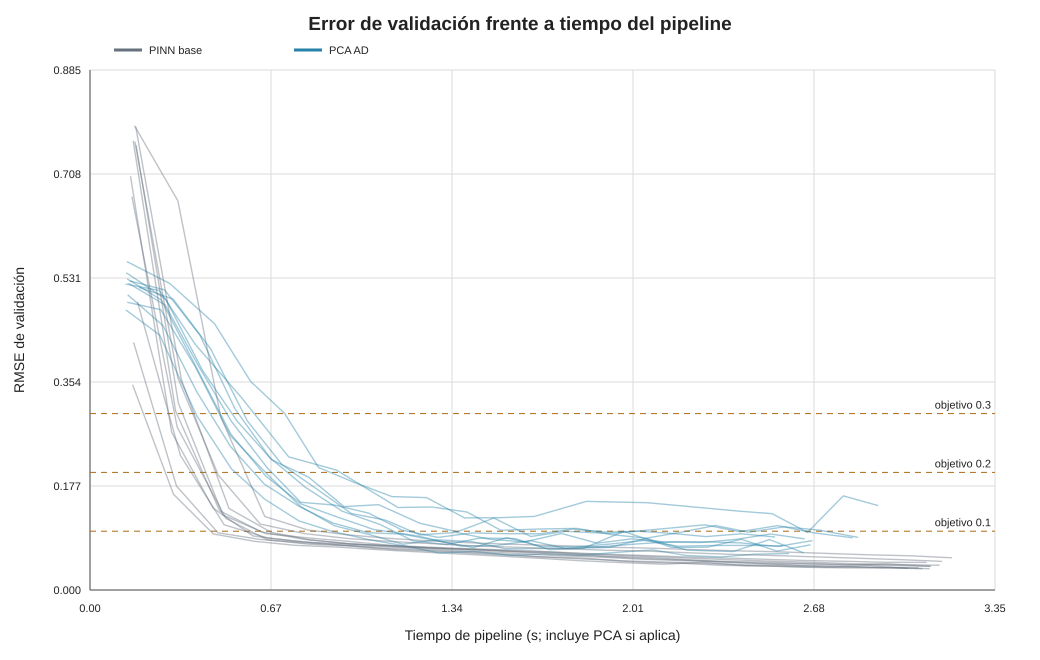

In [5]:
display(SVG(filename=str(RUN_DIR / "validation_vs_time.svg")))


## Lectura inicial

PCA eligió `k=3` y retuvo en promedio 99,66% de la varianza. Su pipeline fue más rápido y el defecto periódico evaluado fue prácticamente cero, pero la PINN base obtuvo menor error de solución y residuo de advección. Esto indica que el umbral de varianza no garantiza por sí solo una base adecuada para derivadas físicas: los modos descartados pueden contribuir poco a la energía y mucho al residuo PDE.

Es un piloto en una ecuación suave y una condición inicial. La siguiente comparación debería barrer `k` (por ejemplo 2, 3, 4, 6, 8) para ver si el residuo baja al retener más modos antes de probar casos de advección más exigentes.


## Reproducir

La configuración está en `configs/advection_base_vs_pca.json`; el ejecutor está en `scripts/run_advection_experiment.py`. El archivo de referencia analítico se genera en `data/generated/advection_periodic.npz` si falta. Ejecuta el script desde la raíz del repositorio para regenerar la corrida.
